# Machine Learning - Practical 2

In [1]:
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.linear_model import LogisticRegression

# Task 1: The Data

We use the mouse protein expression dataset: https://archive.ics.uci.edu/ml/datasets/Mice+Protein+Expression
Please use the code provided below for loading the dataset.

In [2]:
file = 'data/Data_Cortex_Nuclear.csv'
df = pd.read_csv(file)

N = 10  # use only every tenth sample
X_all = df.iloc[::N,1:65].to_numpy()
t_all = (df['Behavior'] == 'S/C').to_numpy()[::N]

idx = ~np.any(np.isnan(X_all), axis=1)
X_all = X_all[idx]
t_all = t_all[idx]

### Tasks 1.1: Dataset Exploration 

Let's start with a bit of exploration.

- How many samples / features are provided?
- How many labels does the dataset have?
- What is the value range of the individuals predictors?
- Visualize the 10 first samples of the dataset in a form that highlights their differences.
- Visualize the variance of each predictor.

In [3]:
# data exploration
print(' Samples:', X_all.shape[0],'\n','Features:', X_all.shape[1],'\n','Labels:', np.unique(t_all))

 Samples: 105 
 Features: 64 
 Labels: [False  True]


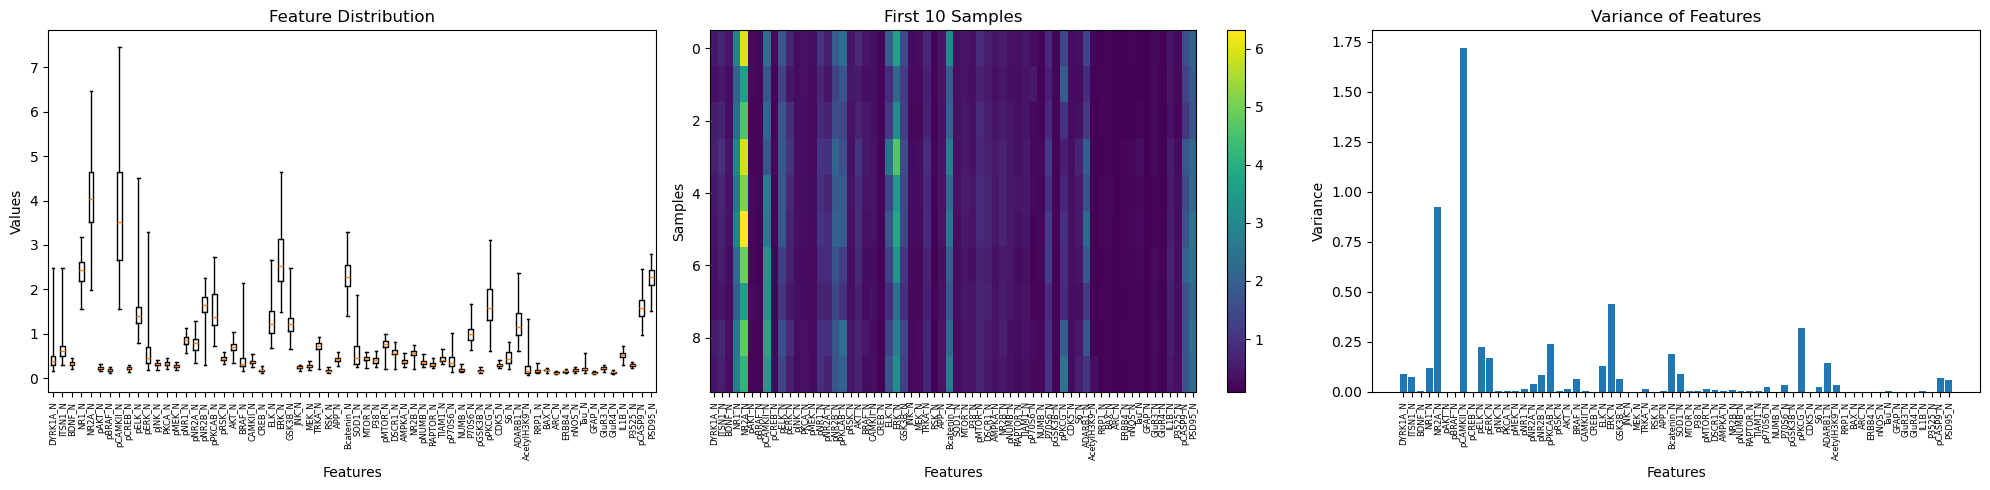

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# 1. Distribution of Features
ax[0].boxplot(X_all, whis=(0, 100))

ax[0].set_title('Feature Distribution')
ax[0].set_xlabel('Features')
ax[0].set_ylabel('Values')
ax[0].set_xticks(range(1, 65))
ax[0].set_xticklabels(df.columns[1:65], rotation=90, fontsize=6)

# 2. First 10 Samples
im = ax[1].imshow(X_all[:10, :], aspect='auto', cmap='viridis')

ax[1].set_title('First 10 Samples')
ax[1].set_xlabel('Features')
ax[1].set_ylabel('Samples')

ax[1].set_xticks(range(64))
ax[1].set_xticklabels(df.columns[1:65], rotation=90, fontsize=6)

fig.colorbar(im, ax=ax[1])

# 3. Variance of Features
variances = np.var(X_all, axis=0)

ax[2].bar(range(64), variances)

ax[2].set_title('Variance of Features')
ax[2].set_xlabel('Features')
ax[2].set_ylabel('Variance')

ax[2].set_xticks(range(64))
ax[2].set_xticklabels(df.columns[1:65], rotation=90, fontsize=6)

plt.tight_layout()
plt.show()

**Task 1.2: Data Preprocessing**:  
- Write a function `split_data(X, y, frac, seed)` that first shuffles your training data and then splits it into a training and a test set. `frac` determines the relative size of the test dataset, `seed` makes sure we get reproducible 
results.  
- Write a function `preprocess(X)` which zero-centers your data and sets variance to one (per-feature).

In [5]:
def split_data(X, y, frac=0.3, seed=None):
    if seed is not None:
        np.random.seed(seed)

    # ---------------- INSERT CODE ----------------------

    # Shuffle data
    indices = np.random.permutation(len(X))
    X_shuffled = X[indices]
    y_shuffled = y[indices]

    # Split data
    n_test = int(len(X) * frac)

    X_train = X_shuffled[:-n_test]
    X_test = X_shuffled[-n_test:]

    y_train = y_shuffled[:-n_test]
    y_test = y_shuffled[-n_test:]


    # ---------------- END CODE -------------------------
    
    return X_train, X_test, y_train, y_test
    
    
def preprocess(X, seed=None):
    if seed is not None:
        np.random.seed(seed)

    # ---------------- INSERT CODE ----------------------

    
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)

    std[std == 0] = 1

    X = (X - mean) / std

    # ---------------- END CODE -------------------------
    
    return X

In [6]:
X_train, X_test, y_train, y_test = split_data(X_all, t_all, frac=0.3, seed=42)

print('Training:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)

Training: (74, 64) (74,)
Test: (31, 64) (31,)


# Task 2: LDA

First, use Linear Discriminant Analysis to separate the classes. As discussed in the Bishop in pg. 186-189, we can find a weight vector $\vec{w}$ that performs a projection of the i-th input data point $\vec{x}_i$

$p =   \vec{w}^T \vec{x}_i$

that optimally separates the classes.

Use the analytic solution to compute the optimal weights $\vec{w}$ from the training set data. 

### Task 2.1

1. Implement a function `compute_lda_weights(x, y)` manually, which carries out LDA using the data `x,y`. 
2. Apply this function on your training data.
3. Visualize the obtained weight vector $\vec{w}$ using a `plt.stemplot`.

Text(0.5, 0, 'predictors')

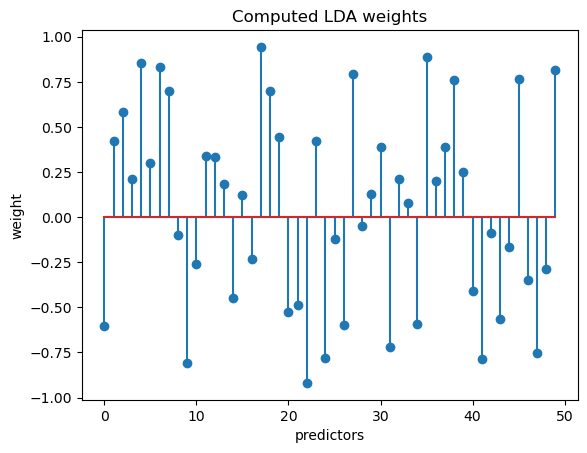

In [7]:
# example usage of stemplot
w_lda = np.random.uniform(-1, 1, 50)  # example data
plt.stem(w_lda.flatten())
plt.title('Computed LDA weights')
plt.ylabel('weight')
plt.xlabel('predictors')

In [8]:
def compute_lda_weights(x, y, alpha=0.001):
    '''function that computes regularized LDA weights for a two class problem

    input:
        x: training data -- array with shape (n_examples x n_features)
        y: training data class label -- flat array with length (n_examples)
        alpha: regularization strength -- float

    output:
        m0: mean of the training examples of class 0 -- flat array with length (n_features)
        m1: mean of the training examples of class 1 -- flat array with length (n_features)
        mdiff: difference of the two class means -- flat array with length (n_features)
        w: regularized LDA weight vector -- flat array with length (n_features)
        '''

    # ---------------- INSERT CODE ----------------------

        # Class means
    m0 = np.mean(x[y == 0], axis=0)
    m1 = np.mean(x[y == 1], axis=0)

    # Difference of class means
    mdiff = m1 - m0

    # Center each class
    x0 = x[y == 0] - m0
    x1 = x[y == 1] - m1

    # Within-class scatter matrix
    Sw = x0.T @ x0 + x1.T @ x1

    # Regularized LDA weights
    w = np.linalg.solve(Sw + alpha * np.eye(x.shape[1]),mdiff)

    # ---------------- END CODE -------------------------

    return m0, m1, mdiff, w

In [9]:
# split dataset and apply LDA
X_train, X_test, y_train, y_test = split_data(X_all, t_all, .3, 42)
X_train_prep = preprocess(X_train)
m0, m1, mdiff, w_lda = compute_lda_weights(X_train_prep, y_train)

Text(0.5, 0, 'predictors')

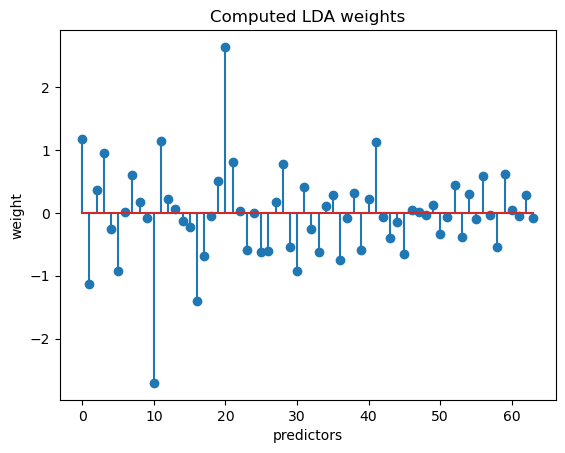

In [10]:
# visualize LDA weights using stemplot
plt.stem(w_lda.flatten())
plt.title('Computed LDA weights')
plt.ylabel('weight')
plt.xlabel('predictors')

### Task 2.2

Project the training data and the test data on $\vec{w}$. Visualize the class separation using a two-color histogram. 
- Is the class separation good?
- Is there a big difference between training and test data?

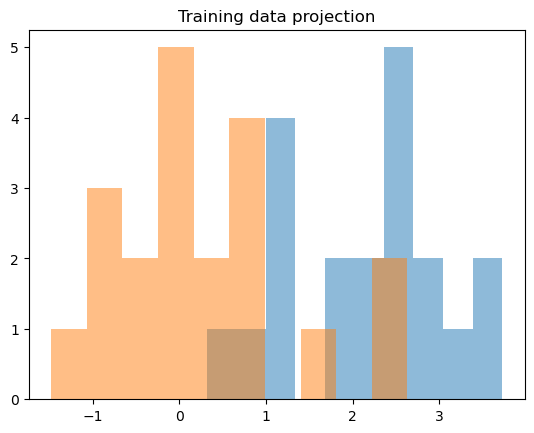

In [11]:
# example usage of histogram
a, b = np.random.normal(2, 1, 20), np.random.normal(0, 1, 20)  # example data

plt.title('Training data projection')
_ = plt.hist(a,label='class 0',alpha=0.5)
_ = plt.hist(b,label='class 1',alpha=0.5)

In [12]:
# compute projections for training and test data
p_train = X_train_prep @ w_lda

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_test_prep = (X_test - mean) / std

p_test = X_test_prep @ w_lda

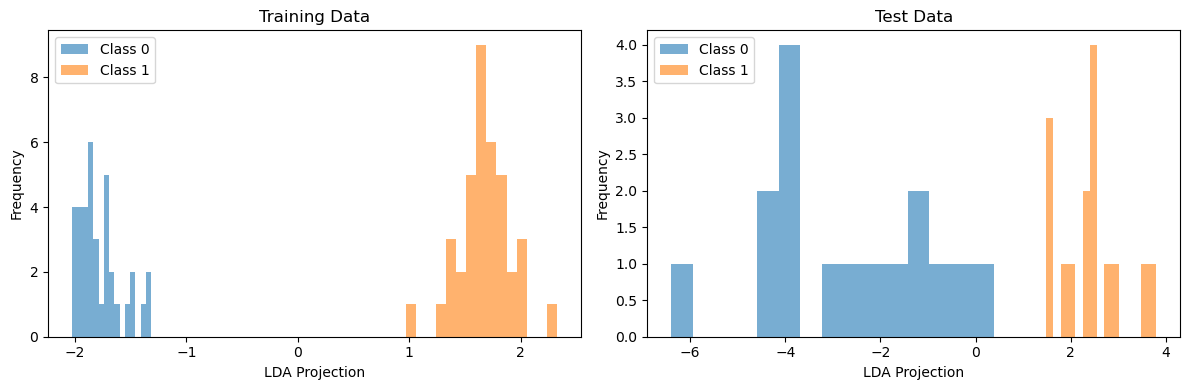

In [13]:
# visualize projections using histogram
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (p, y, title) in enumerate([
    (p_train, y_train, 'Training Data'),
    (p_test, y_test, 'Test Data')
]):
    ax[i].hist(p[y == 0], bins=15, alpha=0.6, label='Class 0')
    ax[i].hist(p[y == 1], bins=15, alpha=0.6, label='Class 1')
    ax[i].set_title(title)
    ax[i].set_xlabel('LDA Projection')
    ax[i].set_ylabel('Frequency')
    ax[i].legend()

plt.tight_layout()
plt.show()

The LDA projection shows a clear separation between the two classes in the training data, with no visible overlap. The test data also shows a good class separation, although the projected values have a substantially larger spread. This difference may indicate some overfitting, but the classes remain well separated in the test set.

### Task 2.3

Now we make class predictions based on the projections. Read https://en.wikipedia.org/wiki/Linear_discriminant_analysis#Fisher's_linear_discriminant and compute threshold $c$ for the projected values $p$ based on the training data. Print the value of $c$ and plot $c$ into the histograms of projected values you made before!

Use $c$ to assign class labels for training and test set. Determine the classification errors (in terms of accuracy) on both datasets and print them. 

In [14]:
def compute_threshold_LDA(m0, m1, w):
    '''Compute the optimal threshold for LDA .

    input:
        m0, m1: mean vectors of the two classes -- flat array with length (n_features)
        w: weight vector of LDA -- flat array with length (n_features)

    output:
        c: the optimal threshold for LDA 
    '''

    # ---------------- INSERT CODE ----------------------

    c = (m0 @ w + m1 @ w) / 2

    # ---------------- END CODE -------------------------
  
    return c


def score_LDA(x_proj, y, c):
    '''Compute the accuracy given a threshold.

    input:
        x_proj: projected data -- flat array with length (n_examples)    
        y: class labels -- flat array with length (n_examples)
        c: optimal threshold for LDA - scalar

    output:
        y_hat: class label predicitons of LDA model -- flat array with length (n_examples)
        acc: classification accuracy
    '''
    # ---------------- INSERT CODE ----------------------

    y_hat = x_proj > c

    acc = np.mean(y_hat == y)

    # ---------------- END CODE -------------------------
    
    return y_hat, acc

In [15]:
# compute optimal threshold
c = compute_threshold_LDA(m0, m1, w_lda)
print('LDA threshold:', c)

LDA threshold: -0.04666076830252697


In [16]:
# compute classification accuracy
y_hat_train, acc_train = score_LDA(p_train, y_train, c)
y_hat_test, acc_test = score_LDA(p_test, y_test, c)

print(f'Training accuracy: {acc_train:.2%}')
print(f'Test accuracy: {acc_test:.2%}')

Training accuracy: 100.00%
Test accuracy: 96.77%


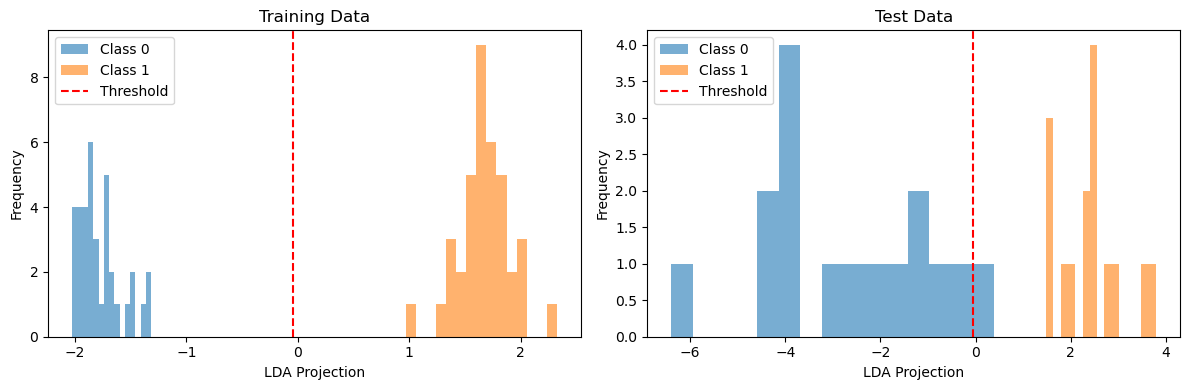

In [17]:
# visualize treshold in histogram
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (p, y, title) in enumerate([
    (p_train, y_train, 'Training Data'),
    (p_test, y_test, 'Test Data')
]):
    ax[i].hist(p[y == 0], bins=15, alpha=0.6, label='Class 0')
    ax[i].hist(p[y == 1], bins=15, alpha=0.6, label='Class 1')
    ax[i].axvline(c, color='red', linestyle='--', label='Threshold')
    ax[i].set_title(title)
    ax[i].set_xlabel('LDA Projection')
    ax[i].set_ylabel('Frequency')
    ax[i].legend()

plt.tight_layout()
plt.show()

## Task 3: Logistic Regression

Next, we will consider classification using Logistic Regression. 

For this task, we will use a different dataset:  
It consists of activations from a convolutional neural network (ResNet18) for images of cats and dogs.
The dataset contains 2,000 samples (i.e. CNN activations) and 256 features (i.e. the CNN activations have 256 dimensions). A target value of 0 indicates a cat, 1 a dog.

Below, you find all imports that are necessary.

In [18]:
X_all, t_all = pickle.load(open('data/cnn_features.pickle', 'rb'))

In [19]:
print('X shape:', X_all.shape)
print('y shape:', t_all.shape)
print('Classes:', np.unique(t_all, return_counts=True))
print('X dtype:', X_all.dtype)

X shape: (2000, 256)
y shape: (2000,)
Classes: (array([0, 1]), array([1000, 1000]))
X dtype: float32


### Task 3.0: Normalize and split the data

Make sure the data has zero mean and variance 1 per feature.

In [20]:
# normalize data
X_train, X_test, y_train, y_test = split_data(X_all, t_all, 0.3, 42)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train_prep = (X_train - mean) / std
X_test_prep = (X_test - mean) / std

print('All means ≈ 0:', np.allclose(X_train_prep.mean(axis=0), 0, atol=1e-5))
print('All variances ≈ 1:', np.allclose(X_train_prep.var(axis=0), 1))

All means ≈ 0: True
All variances ≈ 1: True


### Task 3.1: Iterative Reweighted Least Squares

1. Implement the IRLS algorithm and output at each iteration the current training accuracy. Remember the weight are updated according to:
$$ w' = w - ( \Phi^T R \Phi ) ^ {-1} \Phi^T (y - t)$$
where $y$ is the prediction, $t$ the ground truth target, $R$ the weighting matrix and $\Phi$ the design matrix.  

    Hints:  
    (a) There is a bias term in logistic regression  
    (b) Use a small value for weight init to avoid numerical problems.


2. Apply the IRLS algorithm on data and compute the test accuracy.
3. Compare the results of your implementation to the sklearn implementation of `LogisticRegression(penalty='none')`. Do you get the same result?

In [21]:
# IRLS
from scipy.special import expit

def irls(X, t, max_iter=10, tol=1e-6):
    # Design matrix with bias
    Phi = np.column_stack((np.ones(X.shape[0]), X))

    # Initialize weights
    w = np.zeros(Phi.shape[1])

    for i in range(max_iter):
        # Predicted probabilities
        y = expit(Phi @ w)

        # Weighting matrix (diagonal entries)
        r = y * (1 - y)

        # Gradient and Hessian
        gradient = Phi.T @ (y - t)
        H = Phi.T @ (r[:, None] * Phi)

        # Newton update
        delta = np.linalg.solve(H, gradient)
        w_new = w - delta

        # Training accuracy with updated weights
        y_hat = expit(Phi @ w_new) >= 0.5
        acc = np.mean(y_hat == t)

        print(f'Iteration {i + 1:3d}: Training accuracy = {acc:.2%}')

        # Stopping criterion
        if np.linalg.norm(w_new - w) < tol:
            w = w_new
            break

        w = w_new

    return w

In [22]:
w_irls = irls(X_train_prep, y_train)

Phi_test = np.column_stack((np.ones(X_test_prep.shape[0]), X_test_prep))

y_test_hat = expit(Phi_test @ w_irls) >= 0.5

print(f'Test accuracy (IRLS): {np.mean(y_test_hat == y_test):.2%}')

Iteration   1: Training accuracy = 95.29%
Iteration   2: Training accuracy = 96.50%
Iteration   3: Training accuracy = 97.50%
Iteration   4: Training accuracy = 98.29%
Iteration   5: Training accuracy = 99.64%
Iteration   6: Training accuracy = 100.00%
Iteration   7: Training accuracy = 100.00%
Iteration   8: Training accuracy = 100.00%
Iteration   9: Training accuracy = 100.00%
Iteration  10: Training accuracy = 100.00%
Test accuracy (IRLS): 85.33%


In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(C=np.inf, l1_ratio=0, max_iter=1000, tol=1e-6)
model.fit(X_train_prep, y_train)

print(f'Training accuracy (sklearn): {model.score(X_train_prep, y_train):.2%}')
print(f'Test accuracy (sklearn): {model.score(X_test_prep, y_test):.2%}')

Training accuracy (sklearn): 100.00%
Test accuracy (sklearn): 88.00%


### Comparison of IRLS and scikit-learn

Both implementations achieved **100% training accuracy**. However, IRLS reached a test accuracy of **85.33%**, while scikit-learn achieved **88.00%**.

The results suggest that the training data is linearly separable. In unregularized logistic regression, the weights can continue to grow even after perfect training accuracy has been reached. This can lead to numerical instability and differences in the resulting decision boundaries.

The difference in test accuracy may be explained by the different optimization methods and stopping criteria.

Overall, both implementations perform well, but **perfect training accuracy does not guarantee good generalization** to unseen data.

### Task 3.2: Logistic Regression with Regularization

1. Set sklearn's penalty parameter to `l1` and `l2`. Use the range `np.linspace(0.02, 1, 25)` for the parameter `C`, which controls the strength of regularization. Where is the regularization strongest, for small or big `C`?   
Hint: For `l1` regularization you can use the `saga` solver.
2. Plot strength of regularization over accuracy. Does regularization improve the scores?
3. Visualize the coefficients (or just a subset of all coefficient for a better overview) of the regularized settings and the unregularized setting. What do you observe?
4. Compare the coefficients to the LDA weights.

In [24]:
C_values = np.linspace(0.02, 1, 25)

train_acc_l1 = []
test_acc_l1 = []
train_acc_l2 = []
test_acc_l2 = []

for C in C_values:
    model_l1 = LogisticRegression(C=C, l1_ratio=1, solver='saga', max_iter=5000)
    model_l2 = LogisticRegression(C=C, l1_ratio=0, max_iter=5000)

    model_l1.fit(X_train_prep, y_train)
    model_l2.fit(X_train_prep, y_train)

    train_acc_l1.append(model_l1.score(X_train_prep, y_train))
    test_acc_l1.append(model_l1.score(X_test_prep, y_test))

    train_acc_l2.append(model_l2.score(X_train_prep, y_train))
    test_acc_l2.append(model_l2.score(X_test_prep, y_test))

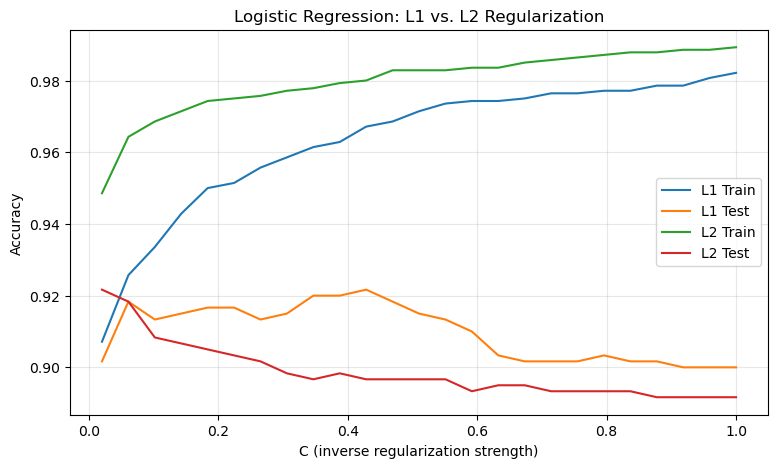

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(C_values, train_acc_l1, label='L1 Train')
plt.plot(C_values, test_acc_l1, label='L1 Test')
plt.plot(C_values, train_acc_l2, label='L2 Train')
plt.plot(C_values, test_acc_l2, label='L2 Test')

plt.xlabel('C (inverse regularization strength)')
plt.ylabel('Accuracy')
plt.title('Logistic Regression: L1 vs. L2 Regularization')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

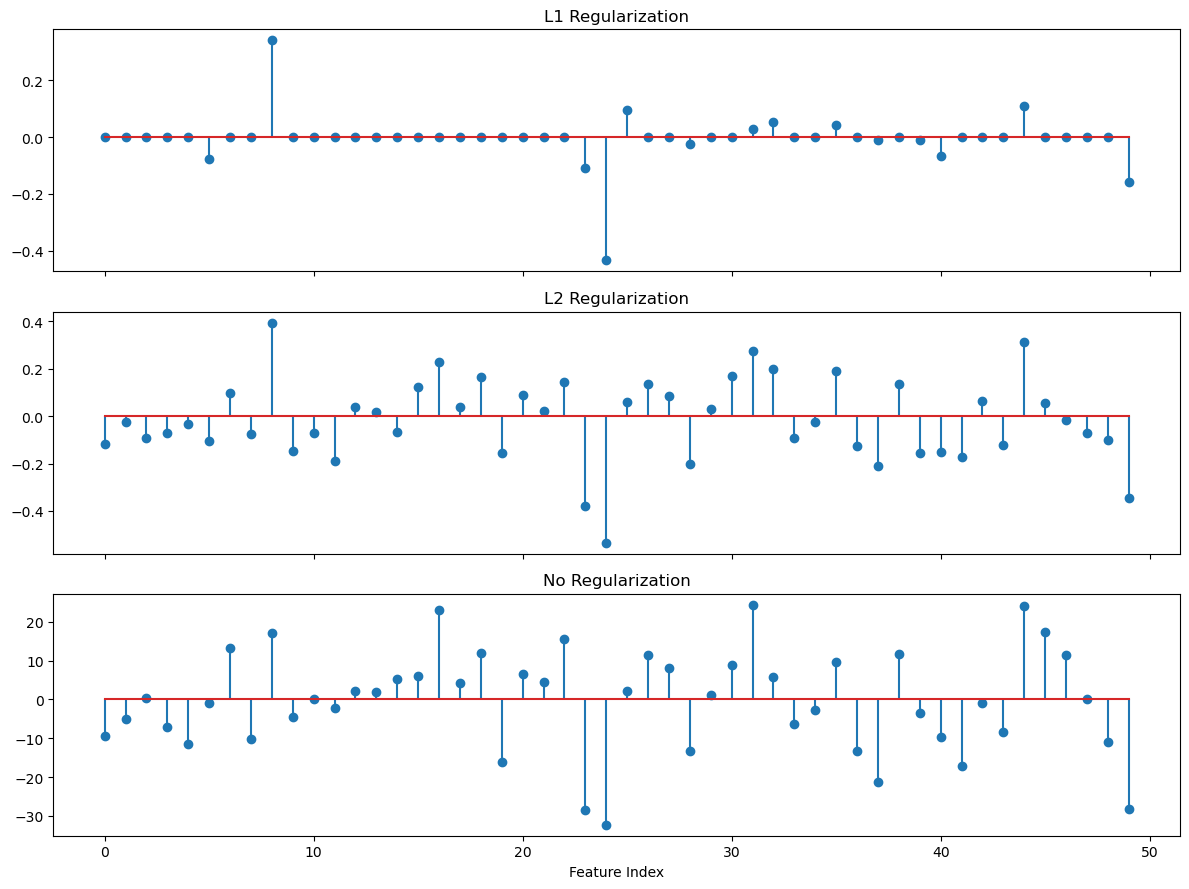

In [26]:
model_l1 = LogisticRegression(C=0.1, l1_ratio=1, solver='saga', max_iter=5000)
model_l2 = LogisticRegression(C=0.1, l1_ratio=0, max_iter=5000)

model_l1.fit(X_train_prep, y_train)
model_l2.fit(X_train_prep, y_train)

weights_l1 = model_l1.coef_[0]
weights_l2 = model_l2.coef_[0]
weights_none = model.coef_[0]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].stem(weights_l1[:50])
axes[0].set_title('L1 Regularization')

axes[1].stem(weights_l2[:50])
axes[1].set_title('L2 Regularization')

axes[2].stem(weights_none[:50])
axes[2].set_title('No Regularization')

axes[2].set_xlabel('Feature Index')
plt.tight_layout()
plt.show()

### Coefficient Comparison

The coefficient plots clearly illustrate the effects of regularization:

- **L1 regularization** produces sparse coefficients, setting many weights exactly to zero and effectively performing feature selection.
- **L2 regularization** reduces the magnitude of the coefficients while keeping most of them nonzero.
- **Without regularization**, the coefficients can become very large, particularly when the training data is linearly separable.

Overall, regularization constrains the model weights and can help reduce overfitting.

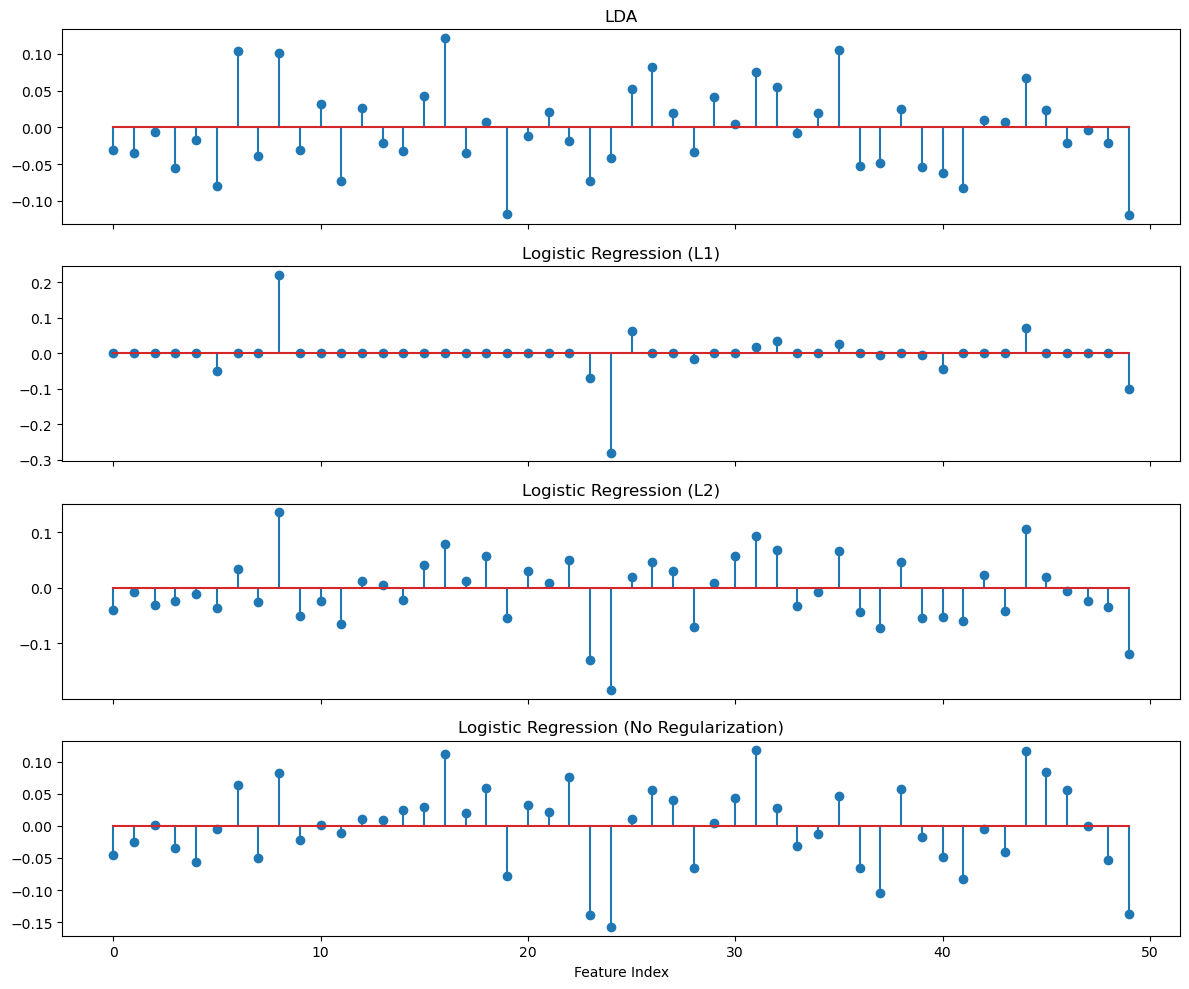

In [27]:
_, _, _, w_lda_cnn = compute_lda_weights(X_train_prep, y_train)

weights = [
    w_lda_cnn,
    weights_l1,
    weights_l2,
    weights_none
]

titles = [
    'LDA',
    'Logistic Regression (L1)',
    'Logistic Regression (L2)',
    'Logistic Regression (No Regularization)'
]

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax, w, title in zip(axes, weights, titles):
    w_norm = w / np.linalg.norm(w)
    ax.stem(w_norm[:50])
    ax.set_title(title)

axes[-1].set_xlabel('Feature Index')
plt.tight_layout()
plt.show()

### Comparison with LDA

The normalized coefficients of LDA and Logistic Regression show similar patterns, with many features having the same coefficient signs.

LDA and L2-regularized Logistic Regression assign nonzero weights to most features, while L1 regularization produces a sparse coefficient vector by setting many weights to zero.

Although the coefficient patterns are similar, their magnitudes differ because the methods use different optimization objectives. LDA maximizes class separation relative to within-class variance, whereas Logistic Regression minimizes the logistic loss.

Overall, both methods identify similar directions for separating the two classes, but regularization changes how strongly individual features contribute to the classification.